# Birefringent Wave Plates

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dschick/udkm1Dsim/blob/develop/examples/06-light/02-birefringence.ipynb)

In this example the polarization change of visible light by a birefringent quartz plate, i.e. a wave plate, is calculated with the exact eigenmodes of an anisotropic dielectric tensor following {cite:t}`berreman1972`, see the [example of the multilayer formalisms](#example_multilayer_formalisms).
The ordinary and extraordinary refractive indices $n_o = 1.54264$ and $n_e = 1.55171$ of crystalline quartz at 633 nm are taken from {cite:t}`ghosh1999`.

:::{admonition} Reference {cite}`ghosh1999`
:class: seealso
G. Ghosh, *Dispersion-equation coefficients for the refractive index and birefringence of calcite and quartz crystals*, [Opt. Commun. 163, 95 (1999)](http://www.doi.org/10.1016/S0030-4018(99)00091-7)
:::

## Setup

Do all necessary imports and settings.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

try:
    import udkm1Dsim as ud
except ImportError:
    %pip install udkm1Dsim
    import udkm1Dsim as ud

u = ud.u  # import the pint unit registry from udkm1Dsim
u.setup_matplotlib()  # use matplotlib with pint units

%matplotlib inline

## Structure

Refer to the [structure example](#example_structure) for more details.

The free-standing quartz plate is a single homogeneous {py:class}`Layer <udkm1Dsim.structures.layers.Layer>` in vacuum.
Its uniaxial {py:class}`Dielectric <udkm1Dsim.structures.dielectric.Dielectric>` is given by the refractive indices perpendicular and parallel to the optic axis, which is along the surface normal $z$ by default.
The `euler_angles` $(\theta, \phi, \psi)$ rotate the crystal by $R = R_z(\phi) R_x(\theta) R_z(\psi)$ as in PyGTM {cite:p}`passler2017`, but in the sample frame of {cite:t}`elzo2012` with $z$ pointing out of the sample.
Here, $\theta = 90°$ tilts the optic axis into the plane of the plate and $\phi = 45°$ rotates it to 45° between the $\sigma$ polarization along $x$ and the plane of incidence $yz$.

In [2]:
n_o = 1.54264
n_e = 1.55171

layer_quartz = ud.Layer(
    "quartz",
    "quartz",
    structural=ud.StructuralParameters(thickness=10 * u.um, density=2648 * u.kg / u.m**3),
    optical=ud.OpticalParameters(
        dielectric=ud.Dielectric(
            eps0=ud.Dispersion.from_ref_index([n_o, n_e]), euler_angles=(90, 45, 0)
        )
    ),
)
layer_quartz.get_dielectric_tensor(633 * u.nm)[0]

array([[ 2.39377105e+00+0.j, -1.40328772e-02+0.j,  1.21518550e-18+0.j],
       [-1.40328772e-02+0.j,  2.39377105e+00+0.j, -1.21518550e-18+0.j],
       [ 1.21518550e-18+0.j, -1.21518550e-18+0.j,  2.37973817e+00+0.j]])

In [3]:
S = ud.Structure("quartz plate")
S.add_sub_structure(layer_quartz, 1)
S.add_substrate(ud.Vacuum(thickness=0 * u.nm))
S

times,sub-structure,thickness
1,quartz,1×10⁴ nm


## Retardance

The light with a polarization along the optic axis propagates with $n_e$ and the one perpendicular to it with $n_o$.
After a single pass through the plate of thickness $d$ at normal incidence, their phase difference is the retardance

$$
\Gamma = \frac{2 \pi}{\lambda} (n_e - n_o) d
$$

so that a quarter-wave plate with $\Gamma = \pi / 2$ converts a linear polarization at 45° to the optic axis into a circular one.
Hence, the ellipticity of the transmitted light is $\epsilon = \frac{1}{2} \arcsin(\sin\Gamma)$.

The ellipticity is calculated from the Jones matrix of the transmission for an incoming $\sigma$ polarization by the {py:class}`BerremanStepanov <udkm1Dsim.simulations.scattering.berreman.BerremanStepanov>` formalism, see {py:meth}`calc_kerr_angles <udkm1Dsim.simulations.scattering.multilayer.MultilayerScattering.calc_kerr_angles>`.

In [4]:
bs = ud.BerremanStepanov(S, True)
bs.save_data = False
bs.disp_messages = False
bs.wl = np.r_[633] * u.nm
bs.theta = np.r_[90] * u.deg  # normal incidence
bs

incoming polarizations set to: sigma
analyzer polarizations set to: unpolarized


parameter,value
force recalc,True
cache directory,./
display messages,False
save data,False
progress bar,True
energy,1.959 eV
wavelength,633 nm
wavenumber,0.009926 1/nm
theta,[90] deg
q_z,[0.01985] 1/nm


In [5]:
thicknesses = np.r_[0.1:50:0.02] * u.um
ellipticity = np.zeros(len(thicknesses))
transmissivity = np.zeros(len(thicknesses))

for i, thickness in enumerate(thicknesses):
    layer_quartz.structural.thickness = thickness
    _, _, T, _ = bs.homogeneous_jones_matrices()
    ellipticity[i] = bs.calc_kerr_angles(T)[1].m_as("deg").item()
    # transmitted intensity of the sigma polarization without analyzer
    transmissivity[i] = np.sum(np.abs(T[0, 0, :, 0]) ** 2)

retardance = (2 * np.pi * (n_e - n_o) * thicknesses / (633 * u.nm)).m_as("")
d_quarter = (633 * u.nm / (4 * (n_e - n_o))).to("um")
print(f"thickness of a quarter-wave plate: {d_quarter:.2f~P}")

thickness of a quarter-wave plate: 17.45 µm


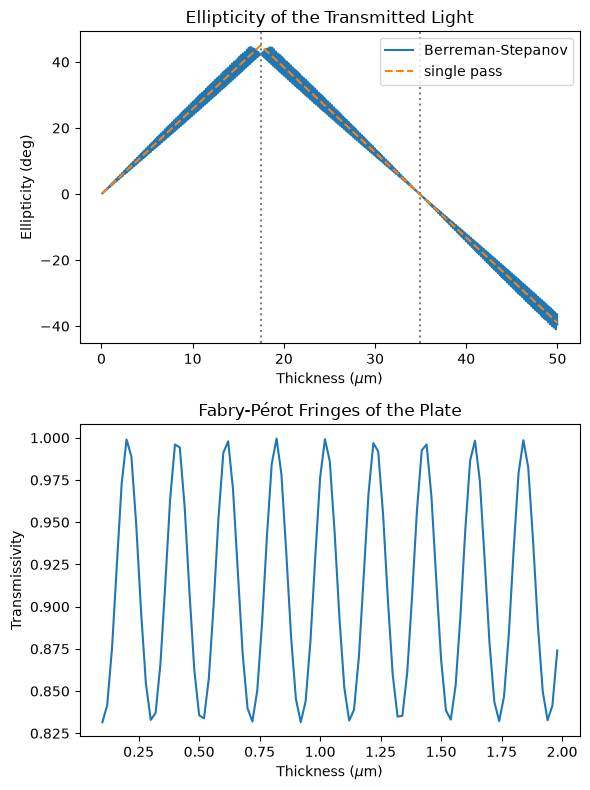

In [6]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
plt.plot(thicknesses, ellipticity, label="Berreman-Stepanov")
plt.plot(thicknesses, np.degrees(0.5 * np.arcsin(np.sin(retardance))), "--", label="single pass")
for n in [1, 2]:
    plt.axvline(n * d_quarter.m, color="gray", ls=":")
plt.xlabel(r"Thickness ($\mu$m)")
plt.ylabel("Ellipticity (deg)")
plt.legend()
plt.title("Ellipticity of the Transmitted Light")

plt.subplot(2, 1, 2)
select = thicknesses < 2 * u.um
plt.plot(thicknesses[select], transmissivity[select])
plt.xlabel(r"Thickness ($\mu$m)")
plt.ylabel("Transmissivity")
plt.title("Fabry-Pérot Fringes of the Plate")

plt.tight_layout()
plt.show()

At the dotted multiples of the quarter-wave thickness, the transmitted light is circularly polarized ($\epsilon = \pm 45°$) or linearly polarized again.
The small oscillations around the single-pass result stem from the multiple reflections at the surfaces of the plate, which also modulate the transmissivity like a Fabry-Pérot etalon with a period of $\lambda / (2n) \approx 205$ nm in thickness.

## Crossed Polarizers

A half-wave plate with $\Gamma = \pi$ between crossed polarizers transmits

$$
T = \sin^2(2\phi) \sin^2\left(\frac{\Gamma}{2}\right)
$$

as function of the azimuth $\phi$ of its optic axis in a single pass.
The analyzer is set to the $\pi$ polarization and the azimuth is rotated by the Euler angle $\phi$.

In [7]:
layer_quartz.structural.thickness = 2 * d_quarter
bs.set_polarization("sigma", "pi")

azimuths = np.r_[0:181:1]
T_crossed = np.zeros(len(azimuths))
for i, azimuth in enumerate(azimuths):
    layer_quartz.optical.dielectric.euler_angles = (90, azimuth, 0)
    T_crossed[i] = bs.homogeneous_reflectivity()[2][0, 0]

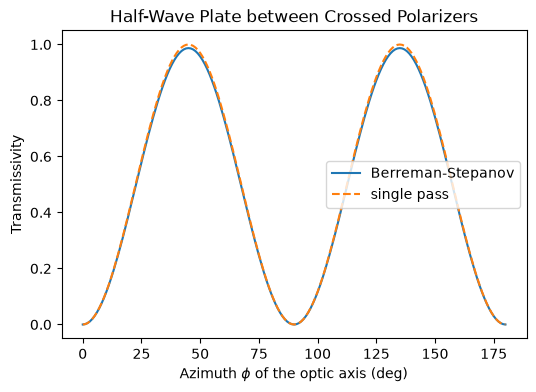

In [8]:
plt.figure(figsize=[6, 4])
plt.plot(azimuths, T_crossed, label="Berreman-Stepanov")
plt.plot(azimuths, np.sin(2 * np.radians(azimuths)) ** 2, "--", label="single pass")
plt.xlabel(r"Azimuth $\phi$ of the optic axis (deg)")
plt.ylabel("Transmissivity")
plt.legend()
plt.title("Half-Wave Plate between Crossed Polarizers")
plt.show()

The transmission through the crossed polarizers is largest for the optic axis at 45° and vanishes along the polarizers.
It is slightly smaller than in a single pass due to the reflection losses at the surfaces of the plate.